# One section: how a human lymph node is organized

This tutorial reads one large tissue section from start to finish. It asks what the section can support,
whether each kind of spatial organization is present, where every gene sits by the length scale and the
strength of its organization, which biology the genes that share a curve shape carry, and where each cell
type sits on the same length scale.

The data are the 10x Genomics Xenium Prime 5K human reactive lymph node (FFPE). Run
`00a_preprocess_lymph_node.ipynb` once first. It quality-controls the section and writes
`~/spectrast_data/xenium_lymph_node_5k.h5ad`, with log-normalised expression in `X`, raw counts in
`layers["counts"]`, cell centroids in micrometres in `obsm["spatial"]` and 10x Genomics' released cell
types in `obs["cell_type"]`. After that quality control the section holds 682,257 cells and 4,623
genes.

**Run time and memory.** On an Apple M3 Max laptop (16 CPU cores, 48 GB of memory shared by CPU and GPU) the notebook ran in 19 minutes on the CPU backend and 10 minutes on the Apple GPU (Metal) backend. On the CPU it needed about 35 GB of memory at its peak. Some steps use part of the panel to keep the
run time and memory down; each one says what it uses and why.

## 1. Load and check the section

In [1]:
import os, hashlib, urllib.request, warnings
import numpy as np, pandas as pd, scanpy as sc, anndata as ad
import matplotlib.pyplot as plt
import spectrast
from spectrast import gr, pl, qc
from spectrast import organization as org

print("spectrast", spectrast.__version__)

def release_gpu_memory():
    # PyTorch keeps GPU memory it has freed in a cache for reuse; hand it back after each heavy step.
    # Does nothing on the CPU backend.
    backend = spectrast.get_backend()
    if backend == "mps":
        import torch
        torch.mps.empty_cache()
    elif backend == "cuda":
        import torch
        torch.cuda.empty_cache()

spectrast 0.16.0


**Choose the backend.** `spectrast.set_backend` decides where the Fourier transforms run; leave one line
active. The CPU backend runs on any machine in double precision, and every number printed in this notebook comes from it. The GPU backends run the Fourier transforms in single precision and are faster (see the run times above). On this section the Apple GPU reproduced every number printed here to within single-precision rounding (scales agree to six significant figures), in about half the time.

In [2]:
spectrast.set_backend("cpu")      # any machine; double precision: the numbers printed in this notebook
# spectrast.set_backend("mps")    # Apple silicon GPU (Metal); single precision
# spectrast.set_backend("cuda")   # NVIDIA GPU; single precision
print("backend:", spectrast.get_backend())

backend: cpu


In [3]:
DATA = os.path.expanduser("~/spectrast_data/xenium_lymph_node_5k.h5ad")   # from 00a_preprocess_lymph_node
adata = sc.read_h5ad(DATA)
adata

AnnData object with n_obs × n_vars = 682257 × 4623
    obs: 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'cell_type', 'sample'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    uns: 'labels', 'log1p', 'platform'
    obsm: 'spatial'
    layers: 'counts'

We use `X` as `00a_preprocess_lymph_node.ipynb` wrote it: every cell scaled to 10,000 counts, then
`log1p`, the log-normalised expression that the package's per-gene nulls and differential test are written
for. Each statistic below standardises every gene before measuring it, so the target sum does not matter,
but the log does: it keeps a few very high counts from dominating a gene's pattern.

`qc.section_report` describes the section before any result is read: the lattice the statistics run on,
and how much of the panel is significant at each radius under the per-gene analytic null. It reports
quantities and issues no pass or fail.

**What is subset, and why.** The report runs on a random 1,000 of the 4,623 genes. Its significance
numbers are fractions over genes, which a random 1,000 estimate to within about a percentage point; on the
CPU the whole panel would add about eleven minutes to this notebook.

.../spectrast/gr.py:1733: UserWarning: pitch-anchored bin 3.39 would need 5.1M lattice bins for this section, over the 4M cap; coarsening to 3.82 (1.1x). This section is now on a relatively coarser grid than others in the same analysis — pass bin_um explicitly if the sections must be strictly comparable.
  b = float(bin_um) if bin_um is not None else _default_bin_um(xy)


bin 3.82 µm, 678,836 occupied bins, 1.01 cells per bin; significant: 88.7% of gene x radius cells, 98.9% of genes at some radius
by radius: 81% of genes significant at 7.6 µm, 95% at 271.2 µm


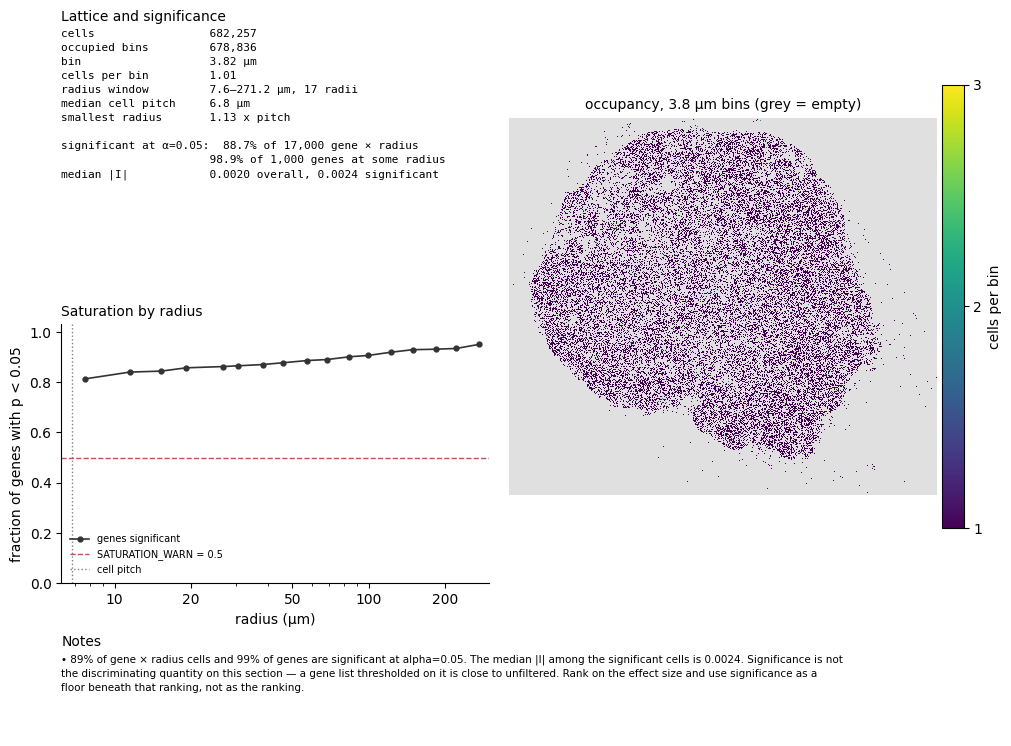

In [4]:
rng = np.random.default_rng(3)
report_genes = sorted(rng.choice(np.asarray(adata.var_names), 1000, replace=False))
rep = qc.section_report(adata, genes=report_genes)
release_gpu_memory()
# every later call that resolves the default lattice repeats the warning below word for word; silence it
warnings.filterwarnings("ignore", message="pitch-anchored bin")
lat, sat = rep["lattice"], rep["saturation"]
print(f"bin {lat['bin_um']:.2f} µm, {lat['n_bins_occupied']:,} occupied bins, {lat['cells_per_bin']:.2f} cells "
      f"per bin; significant: {sat['frac_gene_radius_significant']:.1%} of gene x radius cells, "
      f"{sat['frac_genes_significant_any_radius']:.1%} of genes at some radius")
f_r = sat["by_radius"]["frac_significant"]
print(f"by radius: {f_r[0]:.0%} of genes significant at {lat['r_min_um']:.1f} µm, {f_r[-1]:.0%} at {lat['r_max_um']:.1f} µm")
pl.qc(rep, adata=adata, show=True)

The default lattice bin is half the median spacing between cells, but on this section that would need 5.1
million bins, so the package coarsens it to 3.82 µm and says so in a warning. At that bin the 682,257 cells
occupy 678,836 bins, about one cell per bin; the occupancy map shows the section's outline and the empty
spaces inside it. 88.7% of the gene × radius cells and 98.9% of the 1,000 genes are significant at
α = 0.05, and the fraction of genes rises from 81% at the smallest radius to 95% at the largest. On a
section this large, significance does not tell genes apart, so the rest of this tutorial ranks genes by
the amplitude of their curves and treats significance as a floor.

## 2. Is each kind of organization present?

`gr.fingerprint_presence` measures three statistics for every tested gene, once on the tissue and once on
a copy with the cell positions permuted, and asks with a one-sided rank test whether the tissue's values
are shifted beyond the scramble's. The statistics are the peak of the multiscale Moran curve (how strongly
a gene is organized), focality (how concentrated that organization is) and texture (where the gene's
spatial power sits in frequency; low means smooth).

**What is subset, and why.** We test a random 100 of the 4,623 genes. The call holds the tested genes,
and their scrambled copy, as dense double-precision grids of four million bins with working buffers
beside them, and that memory grows with the number of genes: in our measurements about 20 GB at 100 genes and about 40 GB at 300, so the whole panel is out of
reach on a laptop. The test compares the two distributions across genes, so a random sample of the
panel asks the same question, and 100 genes is well above the 30 below which the call flags itself
underpowered.

In [5]:
rng = np.random.default_rng(0)
presence_genes = sorted(rng.choice(np.asarray(adata.var_names), 100, replace=False))
pres = gr.fingerprint_presence(adata, genes=presence_genes)
release_gpu_memory()
pres

,axis,n_tested,n_sig,n_expected,enrichment,presence_p,score,effect_size,underpowered,present
0,scale_peak_moran,100,85,5.0,17.0,2.401361e-28,0.85,0.070947,False,True
1,focality,100,18,5.0,3.6,1.581876e-02,0.18,0.865474,False,True
2,texture,100,82,5.0,16.4,6.971827e-25,0.82,0.063321,False,True


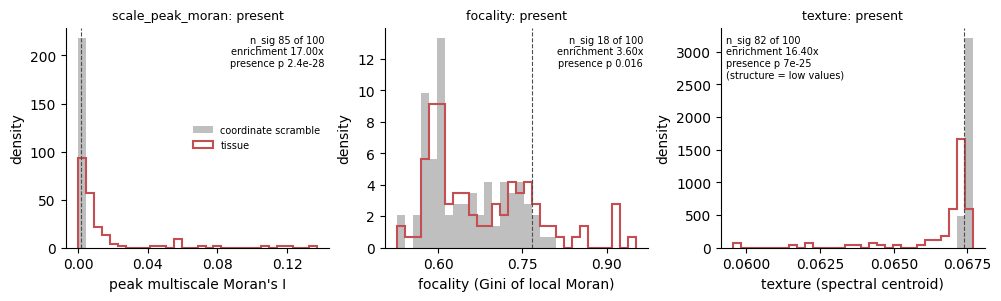

In [6]:
pl.presence(pres, show=True)

Each panel overlays the per-gene statistic on the tissue (red outline) on the same statistic on the
scramble (grey); the dashed line is the scramble's 95th percentile (the 5th for texture, where low values
mean structure). All three statistics read present. The peak Moran's I passes that line for 85 of the 100
genes, 17 times the 5 expected by chance (p = 2e-28), and texture for 82 (p = 7e-25). Focality separates
least from its scramble: 18 genes, 3.6 times chance (p = 0.016).

## 3. Every gene's characteristic scale and amplitude

`organization.organization` measures each gene's Moran's I on one lattice at the 19 default radii, rounded
to whole lattice bins (18 distinct radii on this section), and reduces the curve to two numbers: the characteristic scale r\*, the radius at which the curve has fallen to half its
own range, and the amplitude, the top of that range. A gene whose curve never falls to half its range
inside the window has no r\* (NaN) rather than an extrapolated one.

We run it over the whole panel in blocks of 512 genes, which keeps each block's dense expression to about
3 GB. Every gene's curve is measured on its own, on the same lattice and radii in every block, so the
blocks add up to the same table as one call.

In [7]:
genes = list(adata.var_names)
blocks = [genes[i:i + 512] for i in range(0, len(genes), 512)]
parts = [org.organization(adata, stats=("moran",), genes=b, return_curves=True) for b in blocks]
release_gpu_memory()
tab = pd.concat([t for t, _ in parts], ignore_index=True)
curves = {"radii_um": parts[0][1]["radii_um"],
          "genes": np.concatenate([c["genes"] for _, c in parts]),
          "moran": np.hstack([c["moran"] for _, c in parts])}
print(f"lattice bin {tab.attrs['bin_um']:.2f} µm; {len(curves['radii_um'])} radii from "
      f"{curves['radii_um'][0]:.1f} to {curves['radii_um'][-1]:.1f} µm; "
      f"{int(tab['scale_um'].isna().sum())} of {len(tab):,} genes have no r*")
tab.sort_values("amplitude", ascending=False).head()

lattice bin 3.82 µm; 18 radii from 15.3 to 271.2 µm; 350 of 4,623 genes have no r*


,gene,statistic,scale_um,amplitude,scale_supported,grid_suspect,window_limited,tail_fraction,n_valid_radii
813,CLEC4M,moran,47.266397,0.324809,True,False,False,0.020882,18
893,CR2,moran,88.827212,0.315485,True,False,False,0.067925,18
2394,MARCO,moran,45.855118,0.310894,True,False,False,0.019889,18
981,CXCL13,moran,83.145604,0.298079,True,False,False,0.074859,18
983,CXCL2,moran,47.130687,0.287128,True,False,False,0.020666,18


To see what an unorganized gene looks like on this lattice, we measure the section again with the cell
positions permuted. That keeps every gene's expression values and the tissue's shape, and destroys only
the arrangement. **What is subset, and why.** The scramble is measured for a random 1,000 genes. It only
draws the reference cloud behind the plane, a density estimate that a random fifth of the panel gives at
a fifth of the cost.

In [8]:
rng = np.random.default_rng(1)
scramble_genes = sorted(rng.choice(genes, 1000, replace=False))
scrambled = ad.AnnData(adata.X, var=adata.var[[]])
scrambled.obsm["spatial"] = adata.obsm["spatial"][rng.permutation(adata.n_obs)]
scr = pd.concat([org.organization(scrambled, stats=("moran",), genes=scramble_genes[i:i + 512])
                 for i in range(0, len(scramble_genes), 512)], ignore_index=True)
release_gpu_memory()
del scrambled
print(f"largest amplitude among scrambled genes: {scr['amplitude'].max():.4f}")

largest amplitude among scrambled genes: 0.0017


We read r\* only for genes whose curve has enough amplitude for its shape to mean something: the top 20%
by amplitude, a reading convention rather than a significance test (`gate=` changes it). Focality, the Gini
coefficient of a gene's local-Moran map, is near 0 when the organization is spread evenly and approaches 1
when it sits in a few foci. The plane colours only the read genes, so we compute focality for those.

In [9]:
amp = tab["amplitude"].to_numpy()
gate = np.quantile(amp[np.isfinite(amp)], 0.8)            # what pl.scale_plane(gate=0.8) draws
read = tab.loc[amp >= gate, "gene"].tolist()
r_read = tab.loc[tab["gene"].isin(read), "scale_um"]
print(f"{len(read)} read genes (amplitude >= {gate:.4f}); r* {r_read.min():.0f}-{r_read.max():.0f} µm, "
      f"median {r_read.median():.0f} µm; {int(r_read.isna().sum())} of them have no r*")
print(f"{(amp > scr['amplitude'].max()).mean():.0%} of measured genes exceed every scrambled gene's amplitude")
gr.focality(adata, genes=read)                          # adata.var["spectrast_focality"]
release_gpu_memory()

925 read genes (amplitude >= 0.0127); r* 22-174 µm, median 44 µm; 0 of them have no r*
71% of measured genes exceed every scrambled gene's amplitude


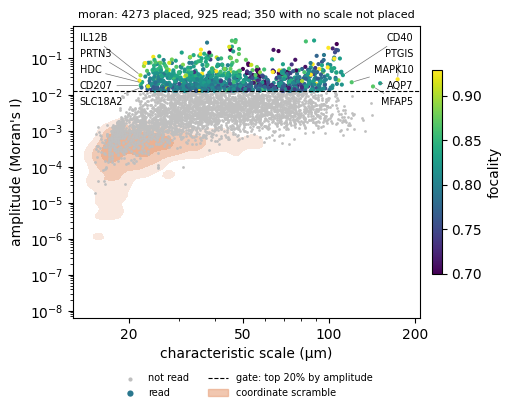

In [10]:
pl.scale_plane(tab, color="spectrast_focality", adata=adata, gate=0.8, scramble=scr, show=True)

Each point is a gene: x is r\*, y the amplitude, both on log axes. The dashed line is the amplitude gate;
the 925 genes above it are read and drawn in colour, and the rest are measured and drawn in grey but not
read. Across the panel, 350 genes never fall to half their range inside the window and are not placed;
every read gene has an r\*. The read genes' r\* runs from 22 to 174 µm, with a median of 44 µm. The
orange cloud is the scramble: its largest amplitude, 0.0017, is about a seventh of the gate, and 71% of the
measured genes lie above it. Focality varies among genes at the same place in the plane, so two genes with
the same r\* and amplitude can be spread evenly or held in a few foci. The five finest and five coarsest
read genes are named.

## 4. Curves against a per-gene null

`gr.moran_null` asks, for each gene at each radius, whether Moran's I exceeds what a random permutation of
that gene's own values over the lattice would give. By default it uses the exact permutation mean and
variance (Cliff and Ord), so it costs about one scalogram; we run it for the read genes. It uses its own
radii, whole multiples of the lattice bin from 2 bins (7.6 µm) up.

We draw three read genes, the one with the largest amplitude in each third of the read genes' r\*.
`pl.curves` reads the scalogram that `gr.fingerprint` stores in `adata.uns`; that scalogram tunes its own
lattice bin for each radius, which on this section costs about 15 s even for three genes, so we compute it
only for the genes drawn. The table compares their r\* on the two lattices.

In [11]:
rt = tab[tab["gene"].isin(read) & tab["scale_um"].notna()]
third = pd.qcut(rt["scale_um"], 3, labels=["finest third", "middle third", "coarsest third"])
show = rt.loc[rt.groupby(third, observed=True)["amplitude"].idxmax(), "gene"].tolist()
fp = gr.fingerprint(adata, genes=show, axes=("scale_um",))
release_gpu_memory()
null = gr.moran_null(adata, genes=read)
release_gpu_memory()
pd.DataFrame({"r* on the plane's lattice (µm)": tab.set_index("gene").loc[show, "scale_um"],
              "r* of the stored scalogram (µm)": fp["scale_um"]}).round(1)

,r* on the plane's lattice (µm),r* of the stored scalogram (µm)
gene,,
CXCL10,35.7,32.3
CLEC4M,47.3,43.9
CR2,88.8,86.1


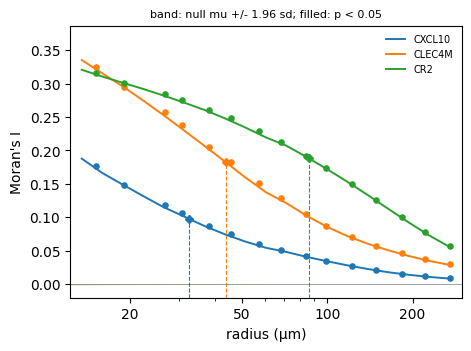

In [12]:
pl.curves(adata, show, null=null, show=True)

The three genes are CXCL10, CLEC4M and CR2. Each line is a gene's curve from the stored scalogram, with its
r\* marked by a diamond and a dashed drop line. The shaded null bands, mean ± 1.96 sd at the null's own
radii, are so narrow that they lie on zero: on a lattice of about 680,000 occupied bins a random
permutation barely moves Moran's I. The markers are the I the null tested, filled where p < 0.05, which is
every one of them. The genes differ in where their curves fall, not only in how high they start: CXCL10
has fallen to half its range by 32 µm, CR2 not until 86 µm. The two lattices put each r\* within 11% of
the other (table above).

100.0% of read gene x radius cells have p < 0.05; p underflows to exactly 0 in 86% of them; 52% of read genes have their largest z at the largest radius


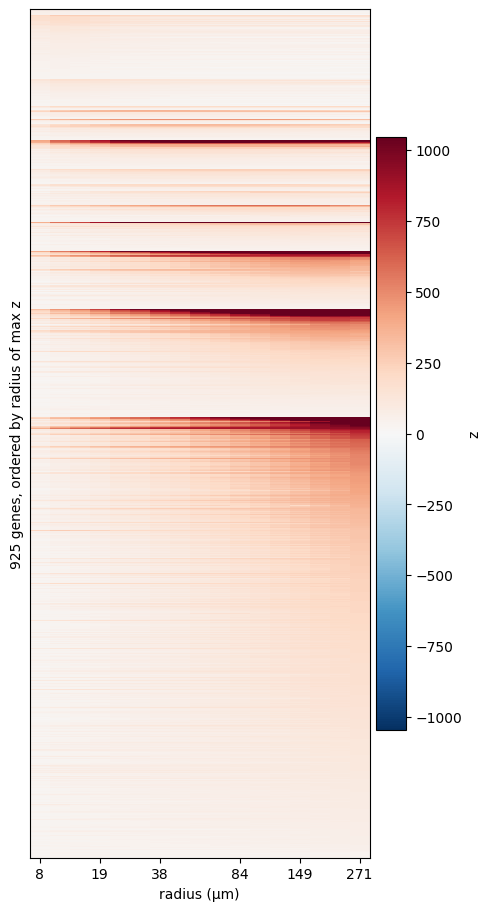

In [13]:
r_zmax = null.loc[null.groupby("gene")["z"].idxmax(), "r_um"]
print(f"{(null['p'] < 0.05).mean():.1%} of read gene x radius cells have p < 0.05; p underflows to exactly 0 "
      f"in {(null['p'] == 0).mean():.0%} of them; {(r_zmax == null['r_um'].max()).mean():.0%} of read genes "
      f"have their largest z at the largest radius")
pl.significance_heatmap(null, value="z", order="zmax", show=True)

Rows are the read genes, ordered by the radius at which their z is largest; colour is z. Every read gene is
significant at every radius, and p underflows to exactly 0 in 86% of the gene × radius cells, which is why
we colour by z rather than by −log10 p. For 52% of the read genes z is largest at the largest radius: the
null's spread shrinks as the neighbourhood grows, so z climbs there even as Moran's I falls. z says how
surely a gene is organized at a radius, not how strongly; the amplitude in section 3 is the strength.

## 5. One gene up close

`pl.gene_card` puts one gene on a page: its expression, its local Moran's I at r\*, and its curves for all
six organization statistics. Without precomputed curves it measures them for this one gene on the same
lattice as the table above, so its Moran r\* is the plane's. We take the read gene with the largest
amplitude.

CLEC4M


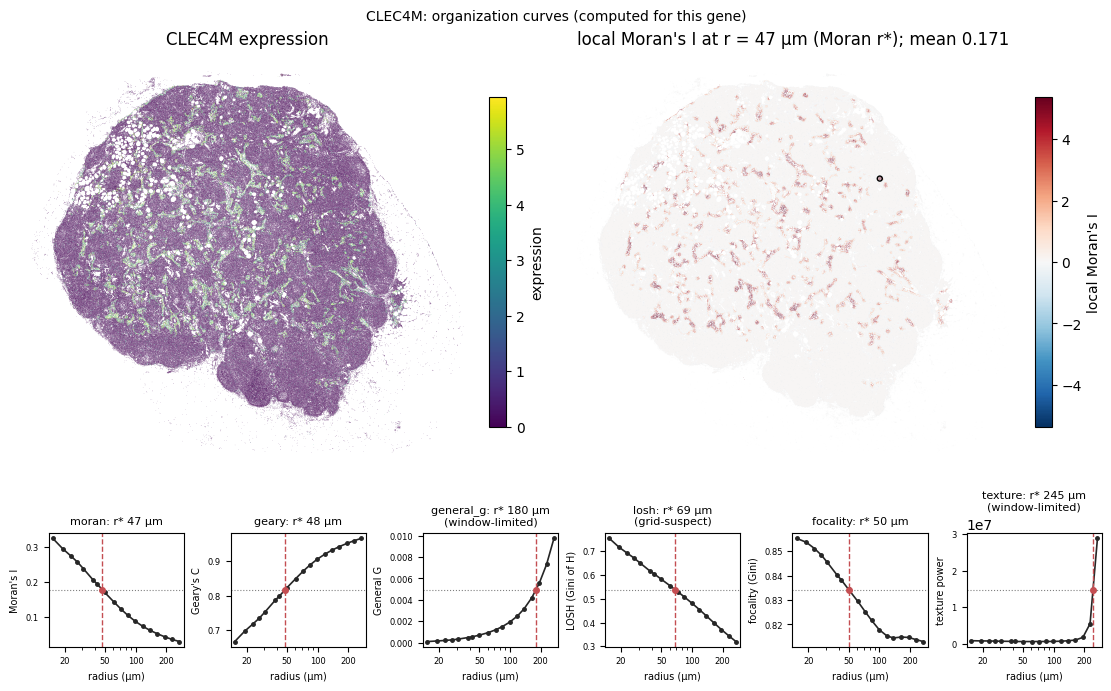

In [14]:
top = tab.sort_values("amplitude", ascending=False)["gene"].iloc[0]
print(top)
pl.gene_card(adata, top, show=True)

CLEC4M encodes a lectin expressed by the endothelium that lines the lymph node's sinuses, and its expression
(left) traces a branching network through the section. Its local Moran's I at r\* = 47 µm (right) is positive
along that network and near zero elsewhere; the map's mean, 0.171, sits close to the curve's half-range level
(the map is drawn on a slightly different lattice). In the bottom row Moran's I and Geary's C give nearly the
same scale, 47 and 48 µm. The titles flag what not to read: the General G and texture curves have not
flattened by the widest radius (window-limited), so their r\* is set by where the sweep stops, and LOSH's
r\* lies within 10% of the radius grid's centre (grid-suspect).

`pl.local_filmstrip` draws the same local Moran map at five radii across the window, each panel on its
own colour scale. We take the coarsest gene drawn in section 4.

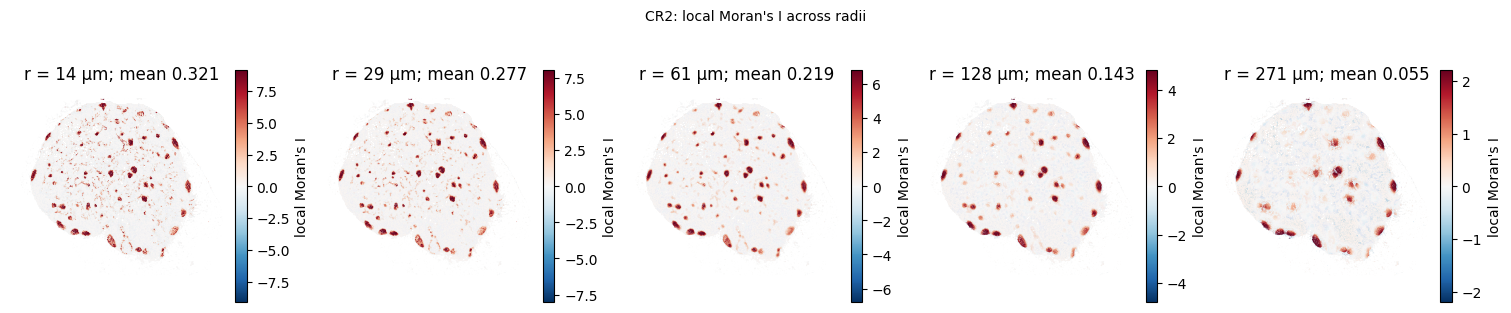

In [15]:
pl.local_filmstrip(adata, show[-1], show=True)

CR2 (CD21) is expressed by B cells and follicular dendritic cells. At 14 µm its local Moran's I is positive in
the follicles and in many small patches between them; as the radius grows the small patches fade and the
follicles remain, and at 271 µm the tissue between follicles turns slightly negative. The mean of each map,
which is the Moran curve's value at that radius, falls from 0.32 to 0.06 across the five panels.

## 6. Curve families and the biology they carry

`pl.curve_families` rescales every read gene's Moran curve to its own range, so that genes group by the
shape of the curve rather than by its height, and splits them into k = 6 families by k-means, numbered
from the finest median r\* to the coarsest. Treat k as a display choice: the families are close to a
binning of r\* itself, so read them as fine-to-coarse bands of genes, not as discrete programmes.

Spectrast does no gene-set work, so the enrichment below is ours, written out in a few lines: a one-sided
hypergeometric test of each Gene Ontology biological process in each family, Benjamini-Hochberg-corrected
within each family. **The background is the measured panel, not the transcriptome.** The 5K panel is a
designed selection of genes; against the whole transcriptome every family would look enriched for whatever
the panel was built to cover. Against the panel, a term is enriched only
if the family holds more of it than the panel's other genes do.

In [16]:
fig, family = pl.curve_families(curves, k=6, gate=0.8, return_labels=True)
plt.close(fig)                       # drawn again below, with the enriched terms
coarsest = family.index[family == family.max()]
print(f"coarsest family, its 12 genes of largest amplitude: "
      + ", ".join(tab.set_index("gene").loc[coarsest, "amplitude"].nlargest(12).index))
pd.DataFrame({"genes": family.value_counts().sort_index(),
              "median r* (µm)": tab.set_index("gene").loc[family.index, "scale_um"].groupby(family).median().round(0)})

coarsest family, its 12 genes of largest amplitude: CR2, CXCL13, MS4A1, SERPINA9, CD79A, CD22, CD19, TNFRSF13C, BANK1, POU2AF1, CD79B, PAX5


,genes,median r* (µm)
family,,
1,106,25.0
2,121,29.0
3,181,37.0
4,165,46.0
5,195,64.0
6,157,89.0


The gene sets are the Bader lab's GO biological-process collection for human without electronically
inferred annotations (IEA), file `Human_GO_bp_no_GO_iea_symbol.gmt` of the November 1, 2026 release. We
download that release's file by its dated address and check its checksum, so the result does not move
when the lab publishes a new release.

In [17]:
GMT_URL = ("https://download.baderlab.org/EM_Genesets/November_01_2026/Human/symbol/GO/"
           "Human_GO_bp_no_GO_iea_symbol.gmt")
GMT = os.path.expanduser("~/spectrast_data/Human_GO_bp_no_GO_iea_symbol_November_01_2026.gmt")
if not os.path.exists(GMT):
    urllib.request.urlretrieve(GMT_URL, GMT)
with open(GMT, "rb") as fh:
    assert hashlib.md5(fh.read()).hexdigest() == "a14a4c94e443afac36e96e9077c10fb1", "unexpected GMT file"

def read_gmt(path):
    # term description -> set of gene symbols; skips the few IDs the release could not name
    sets = {}
    with open(path) as fh:
        for line in fh:
            f = line.rstrip("\n").split("\t")
            if len(f) > 2 and not f[1].startswith("GO ID not found"):
                sets[f[1]] = set(f[2:])
    return sets

def enrich(family, gene_sets, background, min_size=10, max_size=500):
    # one-sided hypergeometric test of every term in every family; BH within each family
    from scipy.stats import hypergeom, false_discovery_control
    bg = set(background)
    sets = {t: s & bg for t, s in gene_sets.items()}
    sets = {t: s for t, s in sets.items() if min_size <= len(s) <= max_size}
    N, rows = len(bg), []
    for f, members in family.groupby(family):
        hits = set(members.index) & bg
        for term, s in sets.items():
            k = len(hits & s)
            rows.append((f, term, k, len(hits), len(s), hypergeom.sf(k - 1, N, len(s), len(hits))))
    res = pd.DataFrame(rows, columns=["family", "term", "overlap", "n_family", "n_term", "p"])
    res["fold"] = (res["overlap"] / res["n_family"]) / (res["n_term"] / N)
    res["q"] = res.groupby("family")["p"].transform(false_discovery_control)
    return res

go_bp = read_gmt(GMT)
background = set(genes) & set().union(*go_bp.values())     # measured genes with at least one annotation
res = enrich(family, go_bp, background)
terms = res[(res["q"] < 0.05) & (res["overlap"] >= 3)]
print(f"{len(go_bp):,} GO BP terms; background: {len(background):,} annotated panel genes; "
      f"{res['term'].nunique():,} terms with 10-500 background genes tested in each family; "
      f"{len(terms)} family x term hits at q < 0.05 (at least 3 genes)")
# nested GO terms share genes, so q ties are common; tied terms may swap places between this table and the plot
terms.sort_values("q").groupby("family").head(3).sort_values(["family", "q"])[
    ["family", "term", "overlap", "n_term", "fold", "q"]]

12,887 GO BP terms; background: 3,825 annotated panel genes; 2,911 terms with 10-500 background genes tested in each family; 312 family x term hits at q < 0.05 (at least 3 genes)


,family,term,overlap,n_term,fold,q
1588,1,regulation of cell motility,37,372,4.004669,2.809112e-11
1886,1,regulation of locomotion,37,383,3.889652,2.809112e-11
852,1,regulation of cell migration,36,360,4.026316,2.809112e-11
3549,2,blood vessel development,16,139,4.785737,3.381857e-04
3536,2,vasculature development,16,148,4.494712,4.101305e-04
4458,2,blood vessel morphogenesis,14,125,4.656522,1.075806e-03
7753,3,inflammatory response,21,196,2.696194,1.386531e-02
7708,3,regulation of locomotion,31,383,2.036811,1.386531e-02
8651,3,positive regulation of tumor necrosis factor p...,10,54,4.660088,1.386531e-02
8864,4,receptor-mediated endocytosis,13,66,5.539773,9.699288e-04


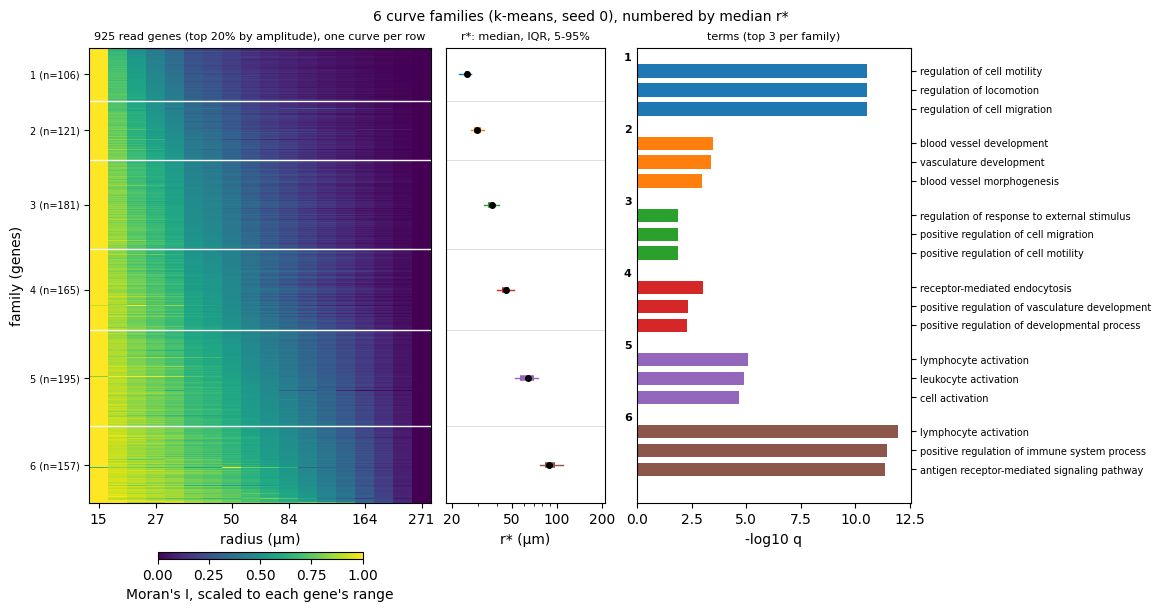

In [18]:
# bars: -log10 q of the three smallest-q terms per family (pass a 'fold' column to rank by fold instead)
pl.curve_families(curves, k=6, gate=0.8, terms=terms[["family", "term", "q"]], show=True)

Left: one row per read gene, its curve scaled to its own range and grouped by family; middle: each family's
r\*; right: the three terms with the smallest q in each family. The families run from a median r\* of
25 µm (106 genes) to 89 µm (157 genes). The finest family is enriched for regulation of cell motility and
migration (q = 3e-11), the second for blood vessel development (q = 3e-4), the third more weakly for
several immune and motility terms (q = 0.01), the fourth for receptor-mediated endocytosis (q = 0.001), and
the fifth and sixth for lymphocyte activation (q = 8e-6 and 1e-12). The coarsest family holds B-cell genes
such as CR2, MS4A1, CD79A and PAX5, with the follicle chemokine CXCL13. These are associations, on this section and against this panel, between a band of
length scales and a gene set; they say which biology sits at which scale, not why.

## 7. Cell types on the same length scale

`organization.celltype_scale` turns each cell type into a 0/1 indicator field (1 in that type's cells,
0 in every other cell) and measures it exactly as a gene: the same lattice, the same radii and the same
half-max reduction, so a type's r\* can be read beside the genes'. We include every type with at least
500 cells. The labels are 10x Genomics' released cell types for this dataset, transferred from CZ
CELLxGENE references: 10x notes that the transfer calls one cluster of MARCO+ macrophages endothelial
cells, and the labels do not separate germinal-centre from mantle-zone B cells.

types with fewer than 500 cells, not measured: [('Neutrophil', 467), ('Erythrocyte', 353)]


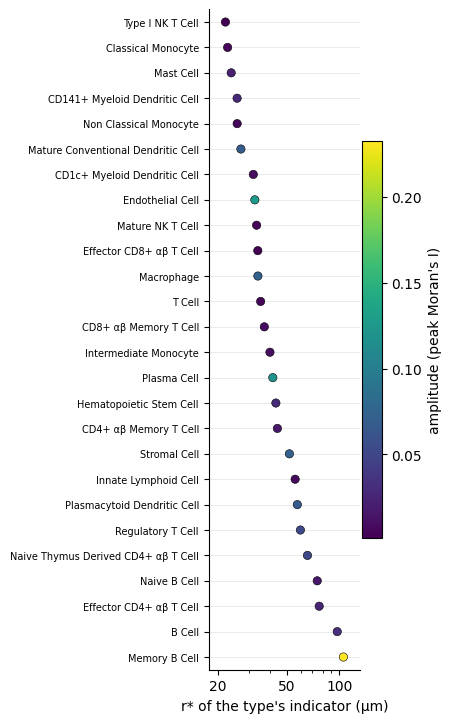

,cell_type,n_cells,scale_um,amplitude
24,Type I NK T Cell,1720,22.1069,0.0015
25,Classical Monocyte,761,22.7483,0.0053
23,Mast Cell,2902,23.8618,0.0216
14,CD141+ Myeloid Dendritic Cell,12520,25.7994,0.0270
22,Non Classical Monocyte,3683,25.8148,0.0051
18,Mature Conventional Dendritic Cell,5098,27.1281,0.0682
16,CD1c+ Myeloid Dendritic Cell,10358,31.9769,0.0091
0,Endothelial Cell,115018,32.6237,0.1276
21,Mature NK T Cell,4413,33.3938,0.0038
19,Effector CD8+ αβ T Cell,5083,33.9281,0.0021


In [19]:
ct = org.celltype_scale(adata, "cell_type", min_cells=500)
print("types with fewer than 500 cells, not measured:", ct.attrs["skipped"])
pl.celltype_ladder(ct, show=True)
ct.sort_values("scale_um")[["cell_type", "n_cells", "scale_um", "amplitude"]].round(4)

Each row is a cell type, finest at the top; the dot sits at the r\* of the type's indicator field and its
colour is the amplitude. The 26 types with at least 500 cells are placed, from type I NK T cells (22 µm)
to B cells (97 µm) and memory B cells (105 µm); neutrophils (467 cells) and erythrocytes (353) fall below 500 after quality control and are not measured. Read the colour before the position: type I NK T
cells and effector CD8+ T cells have amplitudes below 0.003 (the gene gate above was 0.013), so their r\*
says little. The B-cell types sit at the coarse end, near the 89 µm median of the coarsest gene family.
Because germinal-centre and mantle-zone B cells share labels, the structure inside a follicle is not
resolved here, and the endothelial row (33 µm) includes the MARCO+ macrophages that 10x notes were
labelled endothelial.

## Where to go next

Everything here describes one section. Whether a gene's organization changes between conditions, with the
section or the donor as the replicate, is the question of `02_differential.ipynb`.